# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：**歐國澤 **學號／組別：**C114118111 **完成日期：**2026-11-12

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [2]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini；使用題目提供的提示詞詢問平均數與中位數如何受極端值影響，並請用少量具體數字示範。
- AI 回答重點（請自行整理）：平均數會把所有數值加總再除以個數，因此只要出現一個特別大或特別小的極端值，平均數就會被明顯拉高或拉低；中位數只看排序後最中間的位置，只要個數不變，極端值再大也不會改變中間位置的值，因此對極端值較不敏感。
- 我的理解與具體例子：假設 5 位同學的螢幕時間是 `[4, 5, 5, 6, 6]` 小時，這時平均數是 `5.2` 小時，中位數是 `5` 小時。如果最後一位同學變成極端值 `25` 小時（`[4, 5, 5, 6, 25]`），平均數會一口氣被拉高到 `9.0` 小時，但中位數依然維持在正中間的 `5` 小時；在本課 `screen_time_hours` 加入 `15.0` 的異常值後，也能看到平均數略高於中位數。
- 查證來源／方式及日期（無法查證請註明）：對照本單元 4.1 節 `df["screen_time_hours"].mean()` 與 `.median()` 輸出確認，日期：2026-11-20。
- 我檢查或修正 AI 回答的地方：將 AI 舉的薪資範例改寫成貼近本單元螢幕使用時數的 5 筆具體數字，並對照 4.1 節輸出驗證。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


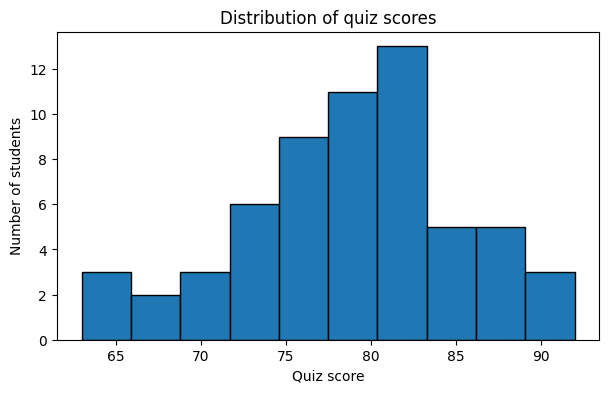

有效成績筆數： 60


In [3]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [4]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：使用上方提供的 Vibe Coding 提示詞，詢問如何繪製 `quiz_score` 排除缺失後的 10 箱直方圖。
- 我補上的程式在做什麼：輸入 `df["quiz_score"].dropna()` 取得 60 筆非缺失成績，透過 `plt.hist(..., bins=10, edgecolor="black")` 將分數切分成 10 個連續區間並畫出各區間人數長條圖（加入黑框讓分箱更清楚）。
- 執行或驗證遇到的問題與修正：沒有報錯，補完後執行 `04-P1` 與驗證 cell 皆順利顯示圖表與檢查訊息。
- 檢查結果及我如何確認：直方圖顯示標題 `Distribution of quiz scores`、橫軸 `Quiz score`、縱軸 `Number of students` 及 10 個分箱，有效成績筆數為 60 筆。


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini；使用題目提供的提示詞詢問直方圖分箱與盒鬚圖各自回答的問題，以及為何離群點不一定是錯誤。
- AI 回答重點（請自行整理）：調整直方圖的 `bins` 只是改變「分數區間切得有多細」，分箱變少（每箱寬度變寬）會讓相鄰的資料合併在一起，柱子變高、形狀變平滑；但底層的原始數據完全沒有改變。另外，直方圖適合看整體分布形狀（如單峰或偏態），盒鬚圖則適合看中位數、四分位距（IQR）與標記可能離群點，而離群點可能是真實存在的極端案例（例如真的每天看螢幕 15 小時），必須查證不能直接刪除。
- 我的理解與具體例子：就像延伸示範程式（`student-04-018`）中把 `quiz_score` 分成 5 箱與 10 箱，`bins=5` 時每箱人數較多、柱子較寬，`bins=10` 時細節較多、高低起伏更明顯，但把各箱人數加總起來永遠都是 `60` 筆，證明資料本身一筆都沒變。而在 4.3 節盒鬚圖中 `screen_time_hours = 15.0` 會被畫成獨立圓點，我們必須先核對資料規格或來源才知道它是事後置入的異常值。
- 查證來源／方式及日期（無法查證請註明）：執行延伸示範 `np.histogram(valid_scores, bins=bins)` 驗證 `counts.sum() == 60` 與 4.3 節盒鬚圖輸出，日期：2026-11-20。
- 我檢查或修正 AI 回答的地方：直接結合延伸示範 `bins=5` 與 `bins=10` 各箱人數加總皆為 60 的程式驗證結果，讓說明更有根據。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


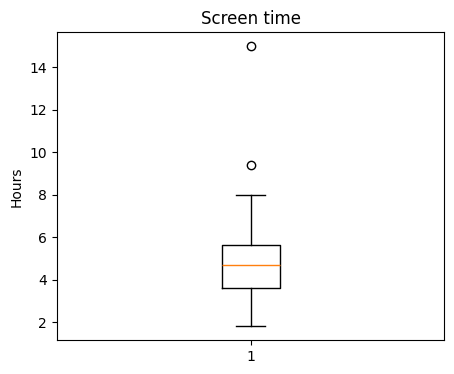

大於 10 小時： 1


In [5]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [6]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。

### ✍️ 本單元收束與 AI 使用紀錄作答
- **關鍵觀念解釋：**探索單變數分布時，要把描述統計量（平均數、中位數、四分位數）與圖表（直方圖、盒鬚圖）搭配起來看；平均數容易被極端值拉動，而直方圖調整 `bins` 只會改變分組呈現的外觀，不會改變原始資料筆數，盒鬚圖標示的離群點也需查證後才能決定處理方式。
- **執行結果及驗證方式：**在 `04-P1` 繪製 `quiz_score` 的 10 箱直方圖並確認有效筆數為 60 筆；在延伸示範中透過 `np.histogram` 驗證 `bins=5` 與 `bins=10` 的各箱人數加總皆等於 60 筆，且 4.3 節盒鬚圖成功標出 `screen_time_hours > 10` 的 1 筆離群點。
- **使用的提示詞：**使用單元內提供的 `04-Q1`、`04-Q2` 查詢提示詞以及 `04-P1` 的 Vibe Coding 提示詞。
- **AI 回答中檢查或修改的地方：**將 AI 說明平均數抗極端值能力與分箱原理的通用例子，改寫成直接對應本資料集 `screen_time_hours`（含 15.0 異常值）與 `quiz_score`（60 筆有效成績）的具體說明。
- **遇到的問題與修正後的證據：**無報錯；補完 `04-P1` 並加入 `edgecolor="black"` 讓分箱邊界更易辨識，執行驗證 cell 確認有效成績筆數為 60 且圖表標籤完整。
- **本資料限制：**本資料集是由固定種子與人為公式生成的 60 筆模擬紀錄，其中的 2 筆睡眠缺失與 1 筆螢幕時間 15.0 小時異常值均在計分後人為加入，因此統計量與圖形分布僅反映模擬規則，不能推論真實學生的成績或作息分布。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


資料形狀（列, 欄）： (60, 7)

各欄位缺失值數量：
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64

螢幕時間超過 10 小時的筆數： 1


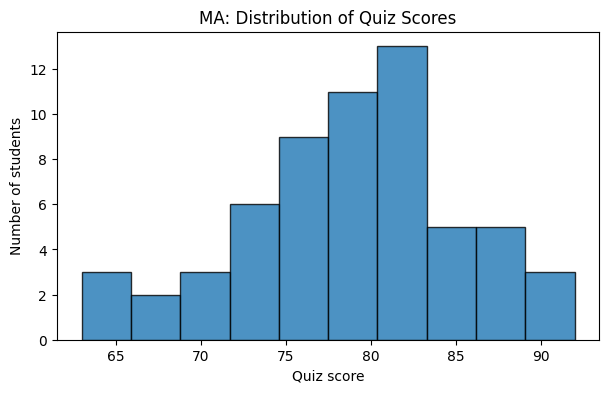

驗證通過：原始 df 完整保留，資料健檢與圖表繪製完成。


In [7]:
# 學生小任務 MA：資料健檢與小考成績直方圖（全程不修改原始 df）

# 1. 輸入：原始資料表 df；處理：檢查資料形狀、各欄缺失數與螢幕時間超過 10 小時的筆數
over_10_count = int((df["screen_time_hours"] > 10).sum())
print("資料形狀（列, 欄）：", df.shape)
print("\n各欄位缺失值數量：")
print(df.isna().sum())
print("\n螢幕時間超過 10 小時的筆數：", over_10_count)

# 2. 輸入：df["quiz_score"] 非缺失數值；處理：繪製 10 箱直方圖；輸出：成績分布圖
valid_quiz = df["quiz_score"].dropna()
plt.figure(figsize=(7, 4))
plt.hist(valid_quiz, bins=10, edgecolor="black", alpha=0.8)
plt.title("MA: Distribution of Quiz Scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()

# 3. 驗證：確認原始 df 筆數與缺失狀態皆未被更動，且有效成績為 60 筆
assert df.shape == (60, 7)
assert int(df["sleep_hours"].isna().sum()) == 2
assert len(valid_quiz) == 60
print("驗證通過：原始 df 完整保留，資料健檢與圖表繪製完成。")


### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：針對模擬學生學習資料表 `df`，檢查整體資料品質（使用全部 7 個欄位檢查缺失，並重點檢視 `sleep_hours` 與 `screen_time_hours`），同時探索小考成績（`quiz_score`）的整體分數分布情形。
- 實際輸出與至少一項依據數字的觀察：資料形狀為 `(60, 7)`（共 60 位學生、7 個欄位）；各欄缺失值中僅 `sleep_hours` 有 `2` 筆缺失，其餘 6 個欄位皆為 `0` 筆缺失；`screen_time_hours` 超過 10 小時的紀錄有 `1` 筆（為 `15.0` 小時）。
- 圖表或模型結果的解讀（依任務要求）：`quiz_score` 的 10 箱直方圖涵蓋全部 60 筆有效成績，整體呈現近似鐘形的單峰分布，多數學生的分數集中在中間區段（約 65～80 分之間），極高分與極低分的學生人數皆較少。
- 資料品質、模擬資料或評估限制：本資料集是由人為公式與固定亂數種子生成的 60 筆模擬資料，且 2 筆 `sleep_hours` 缺失與 1 筆 `screen_time_hours = 15.0` 異常值均在計分後才人為寫入，無法從現有表格還原計分時的原始值，也不能將此分析結果推論為真實學生的表現或因果關係。
- 驗證方法與結果：在程式最後加入三項 `assert` 斷言，驗證 `df.shape == (60, 7)`、`sleep_hours` 缺失仍為 2 筆、以及繪圖用的有效成績筆數為 60 筆，執行後印出「驗證通過：原始 df 完整保留，資料健檢與圖表繪製完成。」。
- AI 工具、實際提示詞、人工修改與遇到的問題：使用 Gemini 並搭配任務提供的提示詞規劃健檢步驟；人工加上 `edgecolor="black"` 讓直方圖分箱邊界更清晰，並補上三項 `assert` 驗證條件；執行過程無報錯。
- 重新執行是否成功及環境或檔案需求：已由上而下重新執行全部儲存格並順利完成；本 Notebook 只需執行頂端的「共用資料準備」cell 即可在記憶體重建完整資料，無需額外外部檔案。
